# vulngraph-gnn: CVE Severity Analysis and Prediction on the Unified Cybersecurity Knowledge Graph

**CS 4330 – Data Science · Fall 2026 · Angelo State University · Dr. Dogdu**

| Team member | Email | Major |
|---|---|---|
| Eryna Plong | rplong@angelo.edu | Computer Science |
| Bunlong Tan | btan@angelo.edu | Computer Science |
| Tanner Love | tlove10@angelo.edu | Artificial Intelligence |

**Repo:** <https://github.com/minty-exit/vulngraph-gnn>

### Project Description

New vulnerabilities (CVEs) are published every day, but the National Vulnerability Database (NVD) often takes weeks or months to assign a severity score. This project combines NVD CVE records with the Unified Cybersecurity Knowledge Graph (UCKG), which links each CVE to its weaknesses (CWE), affected products (CPE) and attack patterns (CAPEC, ATT&CK). We study what drives severity, predict it, and test whether the graph's links improve those predictions, so analysts can prioritize new CVEs before an official score exists.

### Dataset

| Source | URL | Size |
|---|---|---|
| NVD CVE records (NIST) | <https://nvd.nist.gov/developers/vulnerabilities> | 408,816 CVEs (1988–2026), 28 columns; 307,239 have a CVSS v3 severity |
| UCKG (Angelo State University) | <https://doi.org/10.1007/978-3-031-67871-4_2> | 969 CWEs, 559 CAPEC patterns, 921 ATT&CK techniques; 348,049 CVE–CWE and 762,734 CVE–CPE links |

**Schema:**
- **nvd_cves.csv** (one row per CVE): cve_id, published, description, base_score (0–10), severity (LOW, MEDIUM, HIGH, CRITICAL), the 8 CVSS v3 metrics (attack_vector to availability_impact), exploitability_score, impact_score, cwe, vendors, products, plus CVSS v2 and v4 scores.
- **uckg/ nodes:** cwes (cwe_id, name, abstraction, likelihood_of_exploit), capecs (capec_id, name, severity, likelihood), attack_techniques (attack_id, name, domain).
- **uckg/ edges:** edges_cve_cwe, edges_cve_cpe, edges_capec_cwe, edges_capec_attack (pairs of IDs).

### Project Goals

1. Explore the distribution and completeness of CVE severity and CVSS metrics.
2. Identify the features that drive high severity.
3. Predict the CVSS base score from its sub-scores.
4. Group CVEs by description and attributes, and compare the groups with their CWE.
5. Predict a new CVE's severity level before it is scored (Random Forest, XGBoost, GCN), and test whether the graph's links help.

---

## Progress Report 4: Supervised/Unsupervised Learning

Naive Bayes predicts severity from the CVE description (Task 1). Hierarchical and K-Means clustering group CVEs by their attributes and by their descriptions (Task 2).

### Setup

**Libraries and data folder:** the first cell imports the libraries and finds the data folder. On Colab it uses the shared Google Drive folder, and when run locally it uses ../dataset.

In [1]:
#==============================================================
#=========== DO NOT MODIFY THIS CODE CELL =====================
#==============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob, pandas as pd
import seaborn as sns

from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import pdist
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

try:
    # Colab: read the data from the shared Google Drive folder
    from google.colab import drive
    drive.mount('/content/drive')
    DATA = (glob.glob('/content/drive/*/vulngraph-gnn/dataset') + glob.glob('/content/drive/*/*/vulngraph-gnn/dataset'))[0]
except ImportError:
    # Local: the dataset folder sits next to this notebook's folder in the repo
    DATA = '../dataset'

U = f'{DATA}/uckg' # U for UCKG
print('Using', DATA)


Using ../dataset


**Loading the data:** the next cell reads the NVD table (one row per CVE) and the knowledge graph's node and edge tables from the uckg folder.

In [2]:
#==============================================================
#=========== DO NOT MODIFY THIS CODE CELL =====================
#==============================================================

# --- Main table: one row per CVE (label = severity or base_score) # parse_dates=['published', 'last_modified'] converts to real dates ---
nvd = pd.read_csv(f'{DATA}/nvd_cves.csv', parse_dates=['published', 'last_modified'], low_memory=False)

# --- Graph nodes ---
cwes   = pd.read_csv(f'{U}/cwes.csv')
capecs = pd.read_csv(f'{U}/capecs.csv')
attack = pd.read_csv(f'{U}/attack_techniques.csv')

# --- Graph edges ---
cve_cwe      = pd.read_csv(f'{U}/edges_cve_cwe.csv')
cve_cpe      = pd.read_csv(f'{U}/edges_cve_cpe.csv')
capec_cwe    = pd.read_csv(f'{U}/edges_capec_cwe.csv')
capec_attack = pd.read_csv(f'{U}/edges_capec_attack.csv')


**Building df:** the next cell combines the NVD table with four counts from the knowledge graph into one table, df. The steps are explained after the cell.

In [3]:
# --- Combined CVE-level table: NVD + graph counts ---
cve_capec  = cve_cwe.merge(capec_cwe, on='cwe_id')[['cve_id', 'capec_id']].drop_duplicates()
cve_attack = cve_capec.merge(capec_attack, on='capec_id')[['cve_id', 'attack_id']].drop_duplicates()

graph_feats = pd.DataFrame({
    'n_cwe':    cve_cwe.groupby('cve_id').size(),
    'n_cpe':    cve_cpe.groupby('cve_id').size(),
    'n_capec':  cve_capec.groupby('cve_id').size(),
    'n_attack': cve_attack.groupby('cve_id').size(),
})

df = nvd.merge(graph_feats, left_on='cve_id', right_index=True, how='left')
df[graph_feats.columns] = df[graph_feats.columns].fillna(0).astype(int)

# Keep only CVEs that have a v3 label
df = df[df['severity'].notna() & (df['severity'] != 'NONE')]


**What the cell does:**
1. `cve_capec` links each CVE to the CAPEC attack patterns of its CWEs, and `cve_attack` follows those patterns on to ATT&CK techniques.
2. `graph_feats` counts, for each CVE, its linked CWEs (**n_cwe**), affected products (**n_cpe**), CAPEC patterns (**n_capec**) and ATT&CK techniques (**n_attack**).
3. The counts are joined onto the NVD table. CVEs with no links in the graph get 0.
4. CVEs without a CVSS v3 severity are dropped, because every model below needs that label.

"df" is the main table for modeling. It has one row per CVE: all the NVD columns plus the four counts taken from the knowledge graph.

In [4]:
# df is the main data frame and can be seen below
print(f'\n=== df  {df.shape} ===')
display(df.head())



=== df  (307239, 32) ===


,cve_id,published,last_modified,vuln_status,description,cvss3_version,cvss3_source,base_score,severity,vector_string,...,cvss4_base_score,cvss4_severity,cwe,all_cwes,vendors,products,n_cwe,n_cpe,n_capec,n_attack
6,CVE-1999-0084,1990-05-01 04:00:00,2026-06-16 21:47:32.553,Modified,Certain NFS servers allow users to use mknod t...,3.1,Secondary,8.4,HIGH,CVSS:3.1/AV:L/AC:L/PR:N/UI:N/S:U/C:H/I:H/A:H,...,NaN,NaN,CWE-269,CWE-269,sun,sun:nfs,1,1,3,1
92,CVE-1999-0066,1995-07-31 04:00:00,2026-06-16 21:47:29.853,Modified,AnyForm CGI remote execution.,3.1,Secondary,9.8,CRITICAL,CVSS:3.1/AV:N/AC:L/PR:N/UI:N/S:U/C:H/I:H/A:H,...,NaN,NaN,NaN,NaN,john_s._roberts,john_s._roberts:anyform,0,1,0,0
130,CVE-1999-0022,1996-07-03 04:00:00,2026-06-16 21:47:22.167,Modified,Local user gains root privileges via buffer ov...,3.1,Secondary,7.8,HIGH,CVSS:3.1/AV:L/AC:L/PR:L/UI:N/S:U/C:H/I:H/A:H,...,NaN,NaN,CWE-125,CWE-125,bsdi;freebsd;hp;ibm;sgi;sun,bsdi:bsd_os;freebsd:freebsd;hp:hp-ux;ibm:aix;s...,1,2,1,0
171,CVE-1999-0043,1996-12-04 05:00:00,2026-06-16 21:47:26.437,Modified,Command execution via shell metachars in INN d...,3.1,Secondary,9.8,CRITICAL,CVSS:3.1/AV:N/AC:L/PR:N/UI:N/S:U/C:H/I:H/A:H,...,NaN,NaN,CWE-78,CWE-78,bsdi;caldera;isc;nec;netscape;redhat,bsdi:bsd_os;caldera:openlinux;isc:inn;nec:goah...,1,3,5,0
197,CVE-1999-0236,1997-01-01 05:00:00,2026-06-16 21:47:58.393,Modified,ScriptAlias directory in NCSA and Apache httpd...,3.1,Primary,7.5,HIGH,CVSS:3.1/AV:N/AC:L/PR:N/UI:N/S:U/C:H/I:N/A:N,...,NaN,NaN,NaN,NaN,apache;illinois,apache:http_server;illinois:ncsa_httpd,0,1,0,0


df has 307,239 CVEs (one per row) and 32 columns: the NVD columns plus the four graph counts at the end.

### Task 1: Supervised Learning (Naive Bayes)

We use Multinomial Naive Bayes to predict whether a CVE is **severe** (HIGH or CRITICAL) from its **description** alone. The description is available as soon as a CVE is published, before an analyst scores it. Progress Report 2 did the same task with logistic regression and reached 75%.

**Turning text into features:** TF-IDF gives each word and two-word phrase a weight in each description, with the same settings as Progress Report 2. We use the same 80/20 split as Progress Report 3 (random_state=42).

In [5]:
def print_report(y_true, y_pred, **kwargs):
    """classification_report with a line between the per-class rows and the overall rows."""
    lines = classification_report(y_true, y_pred, digits=3, **kwargs).split('\n')
    i = next(i for i, line in enumerate(lines) if line.strip().startswith('accuracy'))
    lines[i - 1] = '-' * max(len(line) for line in lines)
    print('\n'.join(lines))

y_nb = df['severity'].isin(['HIGH', 'CRITICAL']).astype(int)   # 1 = HIGH/CRITICAL, 0 = LOW/MEDIUM
X_train_txt, X_test_txt, y_train_nb, y_test_nb = train_test_split(df['description'], y_nb, test_size=0.2, random_state=42)

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=50000, sublinear_tf=True)
X_train_nb = tfidf.fit_transform(X_train_txt)   # vocabulary learned from training data only
X_test_nb = tfidf.transform(X_test_txt)

print("Training rows:", X_train_nb.shape[0])
print("Testing rows: ", X_test_nb.shape[0])
print("Word features:", X_train_nb.shape[1])

Training rows: 245791
Testing rows:  61448
Word features: 50000


The model learns from 245,791 descriptions (80%) and is tested on 61,448 (20%). Each description is now a row of 50,000 word weights, most of them 0.

**Training the model:** Naive Bayes learns how strongly each word is linked to severe and non-severe descriptions, then picks the more likely class for each test CVE. The baseline always guesses the more common class.

In [6]:
nb = MultinomialNB()
nb.fit(X_train_nb, y_train_nb)
y_pred_nb = nb.predict(X_test_nb)

acc_nb = accuracy_score(y_test_nb, y_pred_nb)
baseline_nb = max(y_test_nb.mean(), 1 - y_test_nb.mean())
print(f"Accuracy: {acc_nb:.4f}   (baseline {baseline_nb:.4f})")
print()
print_report(y_test_nb, y_pred_nb, target_names=['LOW/MEDIUM', 'HIGH/CRITICAL'])

Accuracy: 0.7688   (baseline 0.5463)

               precision    recall  f1-score   support

   LOW/MEDIUM      0.768     0.702     0.734     27879
HIGH/CRITICAL      0.769     0.824     0.796     33569
------------------------------------------------------
     accuracy                          0.769     61448
    macro avg      0.769     0.763     0.765     61448
 weighted avg      0.769     0.769     0.768     61448



Naive Bayes is right on 76.9% of test CVEs, 22 points above the 54.6% baseline. It finds 82% of the HIGH/CRITICAL CVEs (recall 0.824) but only 70% of the LOW/MEDIUM ones.

**Confusion matrix and top words:** the matrix counts correct and wrong predictions for the whole test set. The word lists show which words push a description most toward each class.

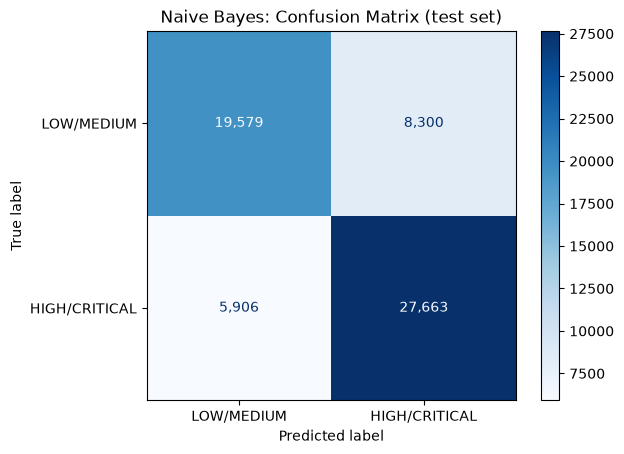

Top HIGH/CRITICAL words: for include, require statement, include require, php program, program php, of filename, the minttoken, minttoken, minttoken function, balance of, contract to, the balance
Top LOW/MEDIUM words:    has xss, admin stored, scripting the, web script, ui thus, thus altering, disclosure within, unfiltered_html, unauth reflected, local information, supplied attributes, scripting it


In [7]:
ConfusionMatrixDisplay.from_predictions(y_test_nb, y_pred_nb, display_labels=['LOW/MEDIUM', 'HIGH/CRITICAL'],
                                        cmap='Blues', values_format=',')
plt.title('Naive Bayes: Confusion Matrix (test set)')
plt.show()

words = np.array(tfidf.get_feature_names_out())
log_ratio = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]   # > 0 means more typical of HIGH/CRITICAL
print("Top HIGH/CRITICAL words:", ', '.join(words[np.argsort(log_ratio)[::-1][:12]]))
print("Top LOW/MEDIUM words:   ", ', '.join(words[np.argsort(log_ratio)[:12]]))

The model misses 5,906 HIGH/CRITICAL CVEs and wrongly flags 8,300 LOW/MEDIUM ones, so most of its mistakes are false alarms. The top HIGH/CRITICAL words come from large families of near-identical CVEs: PHP file-inclusion bugs ("include require statement") and smart-contract token bugs ("minttoken", "balance"). The top LOW/MEDIUM words are cross-site scripting (XSS) phrases.

**Four severity levels:** the project's goal is to predict the exact level (LOW, MEDIUM, HIGH, CRITICAL). We train the same model on the same split with four classes. Macro-F1 averages the F1 score of the four levels equally, so the rare LOW level counts as much as the others.

In [8]:
from sklearn.metrics import f1_score

y_train_4 = df.loc[y_train_nb.index, 'severity']
y_test_4 = df.loc[y_test_nb.index, 'severity']

nb4 = MultinomialNB()
nb4.fit(X_train_nb, y_train_4)
y_pred_4 = nb4.predict(X_test_nb)

acc_4 = accuracy_score(y_test_4, y_pred_4)
f1_4 = f1_score(y_test_4, y_pred_4, average='macro')
print(f"Accuracy: {acc_4:.4f}   (baseline {y_test_4.value_counts(normalize=True).max():.4f})")
print(f"Macro-F1: {f1_4:.4f}")
print()
print_report(y_test_4, y_pred_4, labels=['LOW', 'MEDIUM', 'HIGH', 'CRITICAL'], zero_division=0)

Accuracy: 0.6378   (baseline 0.4310)
Macro-F1: 0.4885



              precision    recall  f1-score   support

         LOW      0.338     0.082     0.133      1395
      MEDIUM      0.721     0.697     0.709     26484
        HIGH      0.608     0.666     0.636     24942
    CRITICAL      0.489     0.465     0.477      8627
-----------------------------------------------------
    accuracy                          0.638     61448
   macro avg      0.539     0.478     0.489     61448
weighted avg      0.634     0.638     0.633     61448



With four levels, accuracy falls to 63.8% (baseline 43.1%) and macro-F1 is 0.49. MEDIUM (F1 0.71) and HIGH (0.64) are predicted best, CRITICAL less well (0.48), and LOW almost never (8% recall), because only 2% of CVEs are LOW.

#### Report:

| Model | Accuracy | Macro-F1 |
|---|---|---|
| Baseline, 2 classes (always HIGH/CRITICAL) | 54.6% | – |
| Naive Bayes, 2 classes | 76.9% | 0.765 |
| Baseline, 4 levels (always MEDIUM) | 43.1% | – |
| Naive Bayes, 4 levels | 63.8% | 0.489 |

**Takeaway:** the description alone separates severe from non-severe CVEs reasonably well, close to Progress Report 2's logistic regression (75%, on a time-based split, so not directly comparable). The model mostly recognizes the vulnerability type and the severity that type usually gets, which is why neighboring levels, and the rare LOW level, are hard to tell apart.

### Task 2: Unsupervised Learning

We group CVEs two ways. **Part A** uses hierarchical clustering on six numeric attributes. **Part B** uses K-Means on the description text and compares the groups with each CVE's weakness type (CWE), as planned in our proposal.

#### Part A: Hierarchical Clustering on CVE Attributes

The attributes are the two CVSS sub-scores (**exploitability_score**, **impact_score**) and the four graph counts (**n_cwe**, **n_cpe**, **n_capec**, **n_attack**). Severity is left out, so we can check afterwards whether the clusters line up with it.

**Note:** the clustering code below is adapted from zyBooks.

**Choosing the attributes:** X holds the six attributes for every CVE.

In [9]:
features = ['exploitability_score', 'impact_score', 'n_cwe', 'n_cpe', 'n_capec', 'n_attack']
X = df[features].dropna()
print("CVEs:", len(X))

CVEs: 307239


All 307,239 CVEs have the six attributes, so no rows are dropped.

**Sampling and scaling:** hierarchical clustering needs the distance between every pair of rows. For all 307,239 CVEs that is about 47 billion distances (~378 GB of memory), so we cluster a random sample of 10,000 (~400 MB). StandardScaler puts every attribute on the same scale.

In [10]:
X_sample = X.sample(n=10000, random_state=42)

scaler = StandardScaler().fit(X)   # fit on all CVEs, apply to the sample
X_scaled = pd.DataFrame(scaler.transform(X_sample), columns=features, index=X_sample.index)
print("Sample:", X_scaled.shape)

Sample: (10000, 6)


The sample has 10,000 CVEs and 6 scaled attributes, so the next cell computes about 50 million distances instead of 47 billion.

**Choosing the linkage:** the zyBooks code uses centroid linkage. We compare it with Ward linkage, which merges the two clusters that add the least spread. Both are cut into 4 clusters.

In [11]:
dist = pdist(X_scaled)

for method in ['centroid', 'ward']:
    labels = fcluster(linkage(dist, method=method), t=4, criterion='maxclust')
    print(f"{method:>8}: cluster sizes {pd.Series(labels).value_counts().sort_index().to_dict()}")

cluster_model = linkage(dist, method='ward')

centroid: cluster sizes {1: 5, 2: 34, 3: 2, 4: 9959}


    ward: cluster sizes {1: 989, 2: 39, 3: 3538, 4: 5434}


Centroid linkage puts 9,959 of the 10,000 CVEs in one cluster, and the other three hold only 41 outliers. Ward gives four usable groups, so we use Ward from here on.

**Dendrogram:** shows the last 30 merges (10,000 leaves would be unreadable). The red line is where the tree is cut into 4 clusters.

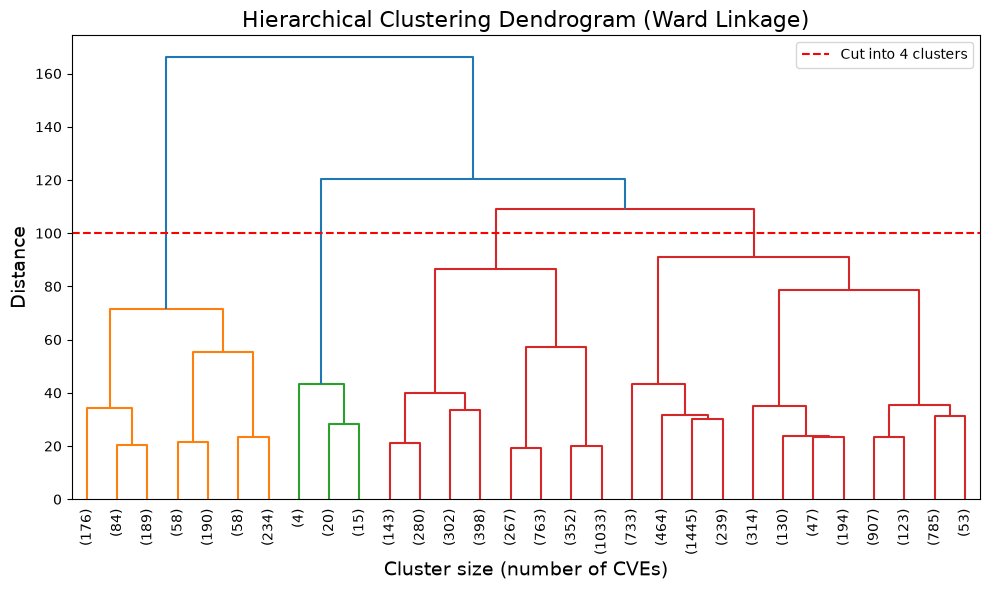

In [12]:
plt.figure(figsize=(10, 6))
dendrogram(cluster_model, truncate_mode='lastp', p=30, leaf_rotation=90)
cut = (cluster_model[-4, 2] + cluster_model[-3, 2]) / 2   # height that leaves 4 clusters
plt.axhline(y=cut, color='red', linestyle='--', label='Cut into 4 clusters')
plt.title('Hierarchical Clustering Dendrogram (Ward Linkage)', fontsize=16)
plt.ylabel('Distance', fontsize=14)
plt.xlabel('Cluster size (number of CVEs)', fontsize=14)
plt.legend()
plt.tight_layout()
plt.show()

The orange branch (989 CVEs) and the green branch (39 CVEs) split off at the largest distances. The red branch holds the other 8,972 CVEs, and the cut divides it in two. These four branches are the 4 clusters below.

**Measuring the clusters:** the silhouette score runs from −1 to 1; higher means CVEs are closer to their own cluster than to the next one. We check it for 2 to 6 clusters, then show the average attributes of each of the 4 clusters.

In [13]:
from sklearn.metrics import silhouette_score

for k in range(2, 7):
    print(f"k = {k}: silhouette = {silhouette_score(X_scaled, fcluster(cluster_model, t=k, criterion='maxclust')):.3f}")

num_clusters = 4
cluster_labels = fcluster(cluster_model, t=num_clusters, criterion='maxclust')

profile = X_sample.assign(Cluster=cluster_labels).groupby('Cluster').mean().round(2)
profile.insert(0, 'CVEs', pd.Series(cluster_labels).value_counts().sort_index())
display(profile)

k = 2: silhouette = 0.488


k = 3: silhouette = 0.498


k = 4: silhouette = 0.226


k = 5: silhouette = 0.246


k = 6: silhouette = 0.288


,CVEs,exploitability_score,impact_score,n_cwe,n_cpe,n_capec,n_attack
Cluster,,,,,,,
1,989,2.87,4.06,1.34,1.39,43.63,15.74
2,39,2.29,4.84,1.03,218.38,11.44,3.08
3,3538,1.92,4.60,0.68,1.19,2.04,0.44
4,5434,3.15,4.03,1.14,1.54,4.81,1.18


Silhouette is highest at k = 2 and 3 (about 0.49), but those cuts keep the two large red-branch groups together; k = 4 (0.23) is the first cut that divides them. Cluster 1 has the most graph links (avg 44 CAPEC patterns, 16 ATT&CK techniques), cluster 2 the most affected products (avg 218 CPEs), and clusters 3 and 4 differ mainly in exploitability (1.92 vs. 3.15).

**Clusters vs. severity:** the share of each severity in each cluster. Severity was not used to build the clusters.

In [14]:
display(pd.crosstab(cluster_labels, df.loc[X_sample.index, 'severity'], normalize='index', rownames=['Cluster']).round(2))

severity,CRITICAL,HIGH,LOW,MEDIUM
Cluster,,,,
1,0.15,0.40,0.04,0.41
2,0.05,0.59,0.00,0.36
3,0.04,0.47,0.04,0.45
4,0.21,0.36,0.01,0.42


HIGH/CRITICAL is 51–64% in every cluster. The biggest difference is CRITICAL: 21% in cluster 4 (high exploitability) versus 4% in cluster 3.

#### Report:

| Cluster | CVEs | What sets it apart | HIGH/CRITICAL | CRITICAL |
|---|---|---|---|---|
| 1 | 989 | Many graph links (avg 44 CAPEC patterns, 16 ATT&CK techniques) | 55% | 15% |
| 2 | 39 | Very many affected products (avg 218 CPEs) | 64% | 5% |
| 3 | 3,538 | Low exploitability (1.92), few graph links | 51% | 4% |
| 4 | 5,434 | High exploitability (3.15) | 57% | 21% |

**Takeaway:** hierarchical clustering finds groups that are easy to describe, but they overlap (silhouette 0.23) and are not severity tiers: they reflect how easy a CVE is to exploit and how well it is linked in the graph. The clusters come from a 10,000-CVE sample, because the method does not scale to all 307,239 CVEs.

#### Part B: K-Means Clustering on Descriptions

K-Means does not need pairwise distances, so it runs on all 307,239 CVEs. We cluster the description text, then check how well the clusters match the CWE labels.

**Text to numbers:** TF-IDF turns each description into word weights (English stop words removed). TruncatedSVD compresses the 20,000 word columns into 100 so K-Means runs quickly, and each row is scaled to length 1 so descriptions are compared by their words, not their length.

In [15]:
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score

tfidf_km = TfidfVectorizer(min_df=5, max_features=20000, sublinear_tf=True, stop_words='english')
X_words = tfidf_km.fit_transform(df['description'])

svd = TruncatedSVD(n_components=100, random_state=42)
X_text = normalize(svd.fit_transform(X_words))
print("Shape:", X_text.shape)

Shape: (307239, 100)


Each of the 307,239 descriptions is now 100 numbers.

**Choosing k:** we run K-Means for several values of k. The silhouette score is computed on a 10,000-CVE sample, because on all CVEs it needs the same pairwise distances as Part A. **NMI** (normalized mutual information, 0 to 1) measures how well the clusters match the CWE labels, using the CVEs that have a CWE.

In [16]:
rng = np.random.default_rng(42)
sil_idx = rng.choice(len(X_text), 10000, replace=False)
has_cwe = df['cwe'].notna().to_numpy()

km_models, km_rows = {}, []
for k in [5, 10, 20, 30]:
    km_models[k] = KMeans(n_clusters=k, n_init=3, random_state=42).fit(X_text)
    labels = km_models[k].labels_
    km_rows.append({'k': k,
                    'silhouette': silhouette_score(X_text[sil_idx], labels[sil_idx]),
                    'NMI with CWE': normalized_mutual_info_score(df['cwe'][has_cwe], labels[has_cwe])})
display(pd.DataFrame(km_rows).set_index('k').round(3))

,silhouette,NMI with CWE
k,,
5,0.060,0.213
10,0.086,0.244
20,0.119,0.276
30,0.142,0.331


Silhouette scores are low (0.06–0.14) and rise slowly with k, so the descriptions do not form clearly separate groups. NMI with CWE also rises with k (0.21 to 0.33). We use k = 20 as a balance between detail and readability.

**Cluster profiles (k = 20):** for each cluster, its size, the words closest to its center, its most common CWE and that CWE's share, and its share of HIGH/CRITICAL CVEs.

In [17]:
km = km_models[20]
words_km = tfidf_km.get_feature_names_out()
centers = svd.inverse_transform(km.cluster_centers_)   # back from 100 columns to word weights

rows = []
for c in range(20):
    in_c = km.labels_ == c
    cwe_share = df.loc[in_c, 'cwe'].value_counts(normalize=True)
    rows.append({'CVEs': in_c.sum(),
                 'top words': ', '.join(words_km[np.argsort(centers[c])[::-1][:5]]),
                 'top CWE': cwe_share.index[0],
                 'CWE share': cwe_share.iloc[0],
                 'HIGH/CRITICAL': df.loc[in_c, 'severity'].isin(['HIGH', 'CRITICAL']).mean()})

km_profile = pd.DataFrame(rows).rename_axis('Cluster').sort_values('CVEs', ascending=False)
with pd.option_context('display.max_colwidth', 60, 'display.width', 200):
    display(km_profile.round(2))

,CVEs,top words,top CWE,CWE share,HIGH/CRITICAL
Cluster,,,,,
4,31837,"issue, affects, discovered, vulnerability, allows",CWE-862,0.12,0.56
8,29391,"version, prior, server, versions, issue",CWE-79,0.07,0.51
12,28065,"code, arbitrary, remote, execute, execution",CWE-22,0.15,0.82
14,25909,"xss, cross, site, scripting, vulnerability",CWE-79,0.84,0.20
19,23780,"access, authentication, allows, password, user",CWE-287,0.08,0.60
0,18510,"service, denial, cause, crafted, allows",CWE-119,0.09,0.57
5,17303,"manipulation, attack, remotely, argument, exploit",CWE-74,0.25,0.59
1,16939,"allow, attacker, vulnerability, exploit, device",CWE-20,0.10,0.59
11,15208,"kernel, linux, following, resolved, fix",CWE-476,0.23,0.44


Clusters built around a vulnerability type match their CWE: the XSS cluster is 84% CWE-79 and the SQL injection cluster is 76% CWE-89. Other clusters form around a vendor's writing style (Oracle, IBM, Microsoft, Chrome, WordPress, Linux kernel) and mix several CWEs. Severity varies widely: 81–86% HIGH/CRITICAL for SQL injection, buffer overflows and code execution, but only 20–30% for XSS and WordPress plugins.

#### Report:

**Takeaway:** K-Means runs on all 307,239 CVEs, and its clusters line up with CWE where the description names the vulnerability type. Unlike Part A's attribute clusters, the text clusters differ strongly in severity, which agrees with Task 1: the vulnerability type in the description carries much of the severity signal.

### Conclusion

| Task | Result |
|---|---|
| 1. Naive Bayes | Description → HIGH/CRITICAL: 76.9% accuracy (baseline 54.6%). Four levels: 63.8%, macro-F1 0.49 |
| 2A. Hierarchical clustering | Ward, 4 clusters on a 10,000-CVE sample: split by exploitability and graph links, silhouette 0.23, little link to severity |
| 2B. K-Means clustering | 20 description clusters on all CVEs: NMI 0.28 with CWE; type-based clusters (XSS, SQL injection) match their CWE and severity |

**What we learned:**
- **Text alone gets about 77% for HIGH/CRITICAL, but only 64% for the exact level.** The model mostly recognizes the vulnerability type, and it almost never predicts the rare LOW level.
- **Hierarchical clustering does not scale.** It needs every pairwise distance, so we had to sample, and centroid linkage was dominated by outliers. K-Means handled all 307,239 CVEs.
- **Descriptions group by vulnerability type and by vendor.** Type-based clusters line up with CWE and severity, while the attribute clusters do not. Our planned GNN will test whether the graph's links, not just their counts, add severity signal.